##          TASK 1: DATA CLEANING & PREPROCESSING

Installing Required Libraries

In [6]:

!pip install -q pandas numpy openpyxl


 Importing Required Libraries

In [7]:

import pandas as pd
import numpy as np
import os
import zipfile

print("Libraries imported successfully!")


Libraries imported successfully!


Verifying Dataset Availability

In [8]:

file_path = "/content/online_retail_II.xlsx"

if os.path.exists(file_path):
    print("Dataset found!")
    print(f"File size: {os.path.getsize(file_path) / (1024 * 1024):.2f} MB")
else:
    print("Dataset not found. Upload the Excel file using the Colab Files panel.")


Dataset found!
File size: 43.51 MB


Checking Dataset File Integrity

In [9]:

if not os.path.exists(file_path):
    print("Please upload the dataset first.")
elif zipfile.is_zipfile(file_path):
    with zipfile.ZipFile(file_path, "r") as z:
        print("ZIP structure: Valid")
        print("Integrity check:", z.testzip())
        print(
            "Workbook exists:",
            "xl/workbook.xml" in z.namelist()
        )
else:
    print("The file does not have a valid Excel ZIP structure.")


ZIP structure: Valid
Integrity check: None
Workbook exists: True


Loading the Online Retail Dataset

In [10]:

df = pd.read_excel(file_path, engine="openpyxl")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 525461
Number of columns: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Inspecting Dataset Structure and Data Types

In [11]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB

Descriptive statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,525461.0,28816.0,537434.0,675.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,525461,4632,85123A,3516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,522533,4681,WHITE HANGING HEART T-LIGHT HOLDER,3549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,525461.0,NaN,NaN,NaN,10.337667,-9600.0,1.0,3.0,10.0,19152.0,107.42411
InvoiceDate,525461,NaN,NaN,NaN,2010-06-28 11:37:36.845017856,2009-12-01 07:45:00,2010-03-21 12:20:00,2010-07-06 09:51:00,2010-10-15 12:45:00,2010-12-09 20:01:00,NaN
Price,525461.0,NaN,NaN,NaN,4.688834,-53594.36,1.25,2.1,4.21,25111.09,146.126914
Customer ID,417534.0,NaN,NaN,NaN,15360.645478,12346.0,13983.0,15311.0,16799.0,18287.0,1680.811316
Country,525461,40,United Kingdom,485852,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Identifying Missing Values

In [12]:

missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
))


,Missing Values,Missing Percentage
Customer ID,107927,20.54
Description,2928,0.56
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


Detecting Duplicate Records

In [13]:

duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)
print("Original number of rows:", len(df))

print("\nSample duplicate records:")
display(df[df.duplicated(keep=False)].head(10))


Total duplicate rows: 6865
Original number of rows: 525461

Sample duplicate records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


Identifying Inconsistent and Invalid Data

In [14]:

print("Unique countries:", df["Country"].nunique())
print("Unique stock codes:", df["StockCode"].nunique())

print("\nNon-positive quantities:",
      (df["Quantity"] <= 0).sum())

print("Non-positive prices:",
      (df["Price"] <= 0).sum())

print("\nRows with missing customer IDs:",
      df["Customer ID"].isnull().sum())

print("\nRows with missing descriptions:",
      df["Description"].isnull().sum())


Unique countries: 40
Unique stock codes: 4632

Non-positive quantities: 12326
Non-positive prices: 3690

Rows with missing customer IDs: 107927

Rows with missing descriptions: 2928


Cleaning and Preprocessing the Dataset

In [15]:

clean_df = df.copy()

# Remove exact duplicate records
clean_df = clean_df.drop_duplicates().copy()

# Standardize text columns
for col in ["Description", "Country", "StockCode"]:
    clean_df[col] = (
        clean_df[col]
        .astype("string")
        .str.strip()
    )

# Correct numerical data types
for col in ["Quantity", "Price"]:
    clean_df[col] = pd.to_numeric(
        clean_df[col], errors="coerce"
    )

# Correct invoice date data type
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"], errors="coerce"
)

# Standardize customer ID representation
clean_df["Customer ID"] = pd.to_numeric(
    clean_df["Customer ID"], errors="coerce"
).astype("Int64")

print("Initial cleaning completed.")
print("Original shape:", df.shape)
print("Cleaned shape:", clean_df.shape)


Initial cleaning completed.
Original shape: (525461, 8)
Cleaned shape: (518596, 8)


Validating the Cleaned Dataset

In [16]:

print("Remaining duplicate rows:",
      clean_df.duplicated().sum())

print("\nRemaining missing values:")
display(clean_df.isnull().sum().to_frame(
    name="Missing Values"
))

print("\nUpdated data types:")
print(clean_df.dtypes)

print("\nFirst five cleaned records:")
display(clean_df.head())


Remaining duplicate rows: 0

Remaining missing values:


,Missing Values
Invoice,0
StockCode,0
Description,2928
Quantity,0
InvoiceDate,0
Price,0
Customer ID,107833
Country,0



Updated data types:
Invoice                object
StockCode      string[python]
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID             Int64
Country        string[python]
dtype: object

First five cleaned records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


Exporting the Cleaned Dataset

In [17]:

output_path = "/content/Online_Retail_Cleaned.csv"

clean_df.to_csv(output_path, index=False)

print("Cleaned dataset exported successfully!")
print("Saved location:", output_path)
print("Exported file size:",
      round(os.path.getsize(output_path) / (1024 * 1024), 2),
      "MB")


Cleaned dataset exported successfully!
Saved location: /content/Online_Retail_Cleaned.csv
Exported file size: 43.16 MB


Downloading the Cleaned Dataset

In [18]:

from google.colab import files

files.download(output_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

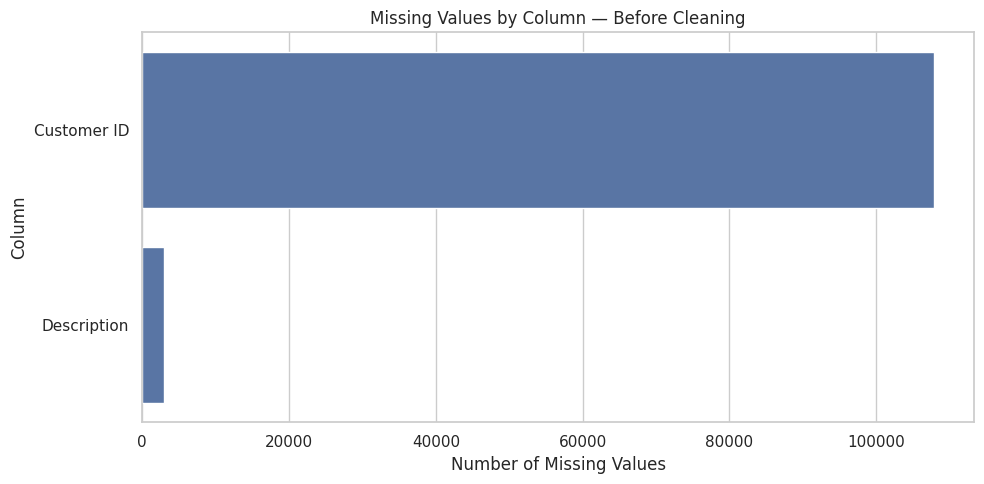

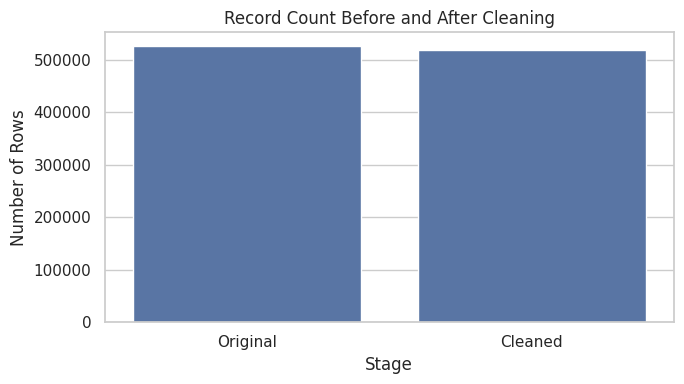

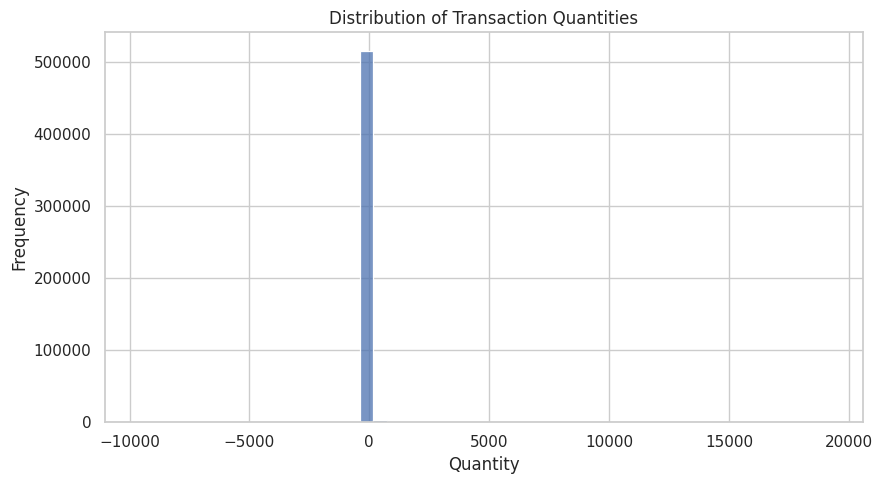

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Missing values before cleaning
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(x=missing.values, y=missing.index)
    plt.title("Missing Values by Column — Before Cleaning")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

# 2. Record count before and after cleaning
comparison = pd.DataFrame({
    "Stage": ["Original", "Cleaned"],
    "Rows": [len(df), len(clean_df)]
})

plt.figure(figsize=(7, 4))
sns.barplot(data=comparison, x="Stage", y="Rows")
plt.title("Record Count Before and After Cleaning")
plt.ylabel("Number of Rows")
plt.tight_layout()
plt.show()

# 3. Quantity distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=clean_df, x="Quantity", bins=50)
plt.title("Distribution of Transaction Quantities")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()